# Stage 3: Co-folding. Can AI Predict the Drug and the Protein Together?
**Project:** Can AI predict how drugs bind? Benchmarking AI structure and co-folding models on COX enzymes.

Stages 1 and 2 looked at proteins alone. Now the real test for drug discovery: give a **co-folding model** only the protein *sequence* and the drug's *SMILES*, and ask it to predict the whole complex. No crystal structure is provided.

We use **Boltz**, an open-source co-folding model in the AlphaFold 3 family. For each prediction we measure:
1. **Protein accuracy:** RMSD to the crystal structure
2. **Ligand pose accuracy:** RMSD to the crystal drug (where a crystal drug exists: celecoxib in COX-2, ibuprofen in COX-1)
3. **Site accuracy:** is the drug in the real binding pocket? (distance to the crystal drug's position)
4. **Mechanism check:** does it touch Arg120, Tyr355, Tyr385, Ser530? How close is Ser530 (the residue aspirin acetylates)?
5. **Confidence:** ipTM and complex pLDDT, and whether confidence tracks correctness

**Runtime:** use a GPU (Runtime → Change runtime type → T4 GPU). Expect roughly 5-15 minutes per prediction; the first run also downloads model weights.

**Works on Colab and Kaggle.** On Kaggle, set Accelerator to **GPU T4 x2** (not P100), switch **Internet on**, and use **Save Version → Save & Run All** for long runs. Both machines have about 16 GB of GPU memory, so a "CUDA out of memory" message needs a bigger GPU.

## 1. Setup

In [5]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"      # use one GPU (Kaggle shows two)
ON_KAGGLE = os.path.exists("/kaggle/working")
if ON_KAGGLE:
    os.chdir("/kaggle/working")
print("Running on:", "Kaggle" if ON_KAGGLE else "Colab or other", "| folder:", os.getcwd())

!pip install -q boltz biopython rdkit pandas matplotlib requests py3Dmol
import torch
print("GPU available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Running on: Kaggle | folder: /kaggle/working
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for dm-tree (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for dm-tree
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> dm-tree
GPU available: True | Tesla T4


In [6]:
# Upgrade build tools first
!pip install --upgrade pip setuptools wheel

# Install dm-tree separately with pre-built binary preference
!pip install -q --prefer-binary dm-tree

# Now install the rest of your packages
!pip install -q boltz biopython rdkit pandas matplotlib requests py3Dmol

  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
Using cached setuptools-84.2.1-py3-none-any.whl (876 kB)
  Attempting uninstall: setuptools
    Found existing installation: setuptools 81.0.0
    Uninstalling setuptools-81.0.0:
      Successfully uninstalled setuptools-81.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cu128 requires setuptools<82, but you have setuptools 84.2.1 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for dm-tree (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for dm-tree
error

In [7]:
# Install Boltz and dependencies without rebuilding dm-tree
!pip install -q boltz biopython rdkit pandas matplotlib requests py3Dmol

# Verify everything loaded correctly
import torch
print("GPU available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for dm-tree (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for dm-tree
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> dm-tree
GPU available: True | Tesla T4


In [8]:
# 1. Upgrade core packaging tools
!pip install --upgrade pip setuptools wheel

# 2. Force installation of pre-built dm-tree binary
!pip install dm-tree --only-binary=:all:

# 3. Install Boltz with CUDA support and remaining dependencies
!pip install boltz[cuda] biopython rdkit pandas matplotlib requests py3Dmol -U

# 4. Verify GPU connection
import torch
print("GPU available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

  Using cached pandas-3.1.0-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (18 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached numpy-1.26.4-cp313-cp313-linux_x86_64.whl
  Using cached hydra_core-1.3.2-py3-none-any.whl.metadata (5.5 kB)
  Using cached pytorch_lightning-2.5.0-py3-none-any.whl.metadata (21 kB)
  Using cached dm-tree-0.1.8.tar.gz (35 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached requests-2.32.3-py3-none-any.whl.metadata (4.6 kB)
  Using cached einops-0.8.0-py3-none-any.whl.metadata (12 kB)
  Using cached einx-0.3.0-py3-none-any.whl.metadata (6.9 kB)
  Using cached mashumaro-3.14-py3-none-any.whl.metadata (114 kB)
  Using cached modelcif-1.2-py3-none-any.whl
  Using cached wandb-0.18.7-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (9.7 kB)
  Using c

In [9]:
# Install boltz and helper packages without forcing the broken old dependency build
!pip install --no-deps boltz
!pip install biopython rdkit pandas matplotlib requests py3Dmol

# Verify everything loaded correctly and GPU is active
import torch
print("GPU available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")



GPU available: True | Tesla T4


In [10]:
!pip install -q mashumaro gemmi hydra-core einx fairscale modelcif wandb pytorch-lightning

In [11]:
!pip install -q boltz biopython rdkit pandas matplotlib requests py3Dmol mashumaro gemmi hydra-core einx fairscale modelcif wandb pytorch-lightning

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for dm-tree (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for dm-tree
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> dm-tree


In [12]:
# 1. Install all helper libraries and dependencies using pre-built binaries
!pip install -q biopython rdkit pandas matplotlib requests py3Dmol mashumaro gemmi hydra-core einx fairscale modelcif wandb pytorch-lightning

# 2. Install Boltz without triggering the broken dependency build
!pip install --no-deps boltz

# 3. Verify GPU connection
import torch
print("GPU available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU available: True | Tesla T4


In [29]:
import os, glob, json, requests
import numpy as np, pandas as pd, matplotlib.pyplot as plt, py3Dmol
from Bio import Align
from Bio.PDB import PDBParser, PDBIO, Select, Superimposer
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolAlign

THREE2ONE = {"ALA":"A","ARG":"R","ASN":"N","ASP":"D","CYS":"C","GLN":"Q","GLU":"E","GLY":"G","HIS":"H",
             "ILE":"I","LEU":"L","LYS":"K","MET":"M","PHE":"F","PRO":"P","SER":"S","THR":"T","TRP":"W",
             "TYR":"Y","VAL":"V","MSE":"M"}
SKIP = {"HOH","HEM","NAG","BMA","MAN","FUC","GOL","SO4","EDO","BOG","NA","CA","CL"}

def xyz(ls):
    return np.array([[float(l[30:38]), float(l[38:46]), float(l[46:54])] for l in ls])

def seq_of(residues):
    return "".join(THREE2ONE.get(r.get_resname(), "X") for r in residues)

exact = Align.PairwiseAligner()
exact.mode = "global"
exact.match_score, exact.mismatch_score = 2, -1
exact.open_gap_score, exact.extend_gap_score = -5, -0.5
exact.end_gap_score = 0.0

def align_pairs(a, b):
    aln = exact.align(a, b)[0]
    pairs = []
    for (a0, a1), (b0, b1) in zip(*aln.aligned):
        pairs += list(zip(range(a0, a1), range(b0, b1)))
    return pairs

## 2. Load the sequences and crystal structures (the answer key)

In [14]:
def load_experimental(key, pdb_id, prefer):
    text = requests.get(f"https://files.rcsb.org/download/{pdb_id}.pdb", timeout=30).text
    lines = text.splitlines()
    groups = {}
    for l in lines:
        if l.startswith("HETATM") and l[16] in " A" and l[17:20].strip() not in SKIP:
            groups.setdefault((l[17:20].strip(), l[21]), []).append(l)
    choice = next((k for p in prefer for k in groups if k[0] == p), None) or max(groups, key=lambda k: len(groups[k]))
    lig_name, chain_id = choice
    lig = groups[choice]
    seq = "".join(THREE2ONE.get(r, "X") for l in lines if l.startswith("SEQRES") and l[11] == chain_id
                  for r in l[19:].split())
    atoms = [l for l in lines if l.startswith("ATOM") and l[21] == chain_id and l[16] in " A"]
    open(f"exp_{key}.pdb", "w").write("\n".join(atoms) + "\nEND\n")
    open(f"exp_{key}_view.pdb", "w").write("\n".join(atoms + lig) + "\nEND\n")
    s = PDBParser(QUIET=True).get_structure(key, f"exp_{key}.pdb")
    res = [r for r in s[0][chain_id] if r.id[0] == " " and "CA" in r]
    pairs = align_pairs(seq, seq_of(res))
    res_to_seq = {e: si for si, e in pairs}
    return {"key": key, "pdb_id": pdb_id, "lig_name": lig_name, "lig": lig, "lig_xyz": xyz(lig),
            "seq": seq, "res": res, "res_to_seq": res_to_seq,
            "resseq_to_seq": {res[e].id[1]: si for e, si in res_to_seq.items()}}

EXP = {"cox1": load_experimental("cox1", "1EQG", ["IBP"]),
       "cox2": load_experimental("cox2", "3LN1", ["CEL", "S58"])}
for k, e in EXP.items():
    print(f"{k}: {e['pdb_id']} | crystal ligand {e['lig_name']} | length {len(e['seq'])} | unknown residues {e['seq'].count('X')}")

cox1: 1EQG | crystal ligand IBP | length 580 | unknown residues 0
cox2: 3LN1 | crystal ligand CEL | length 587 | unknown residues 0


## 3. Choose the predictions
Each job is (enzyme, drug). Only **celecoxib in COX-2** and **ibuprofen in COX-1** have a crystal ligand to compare the pose against. Aspirin has no crystal ligand here, so it is judged by whether it lands in the real pocket and near Ser530.

Add more jobs to the list if you have time (each takes several minutes). Good extras: `("cox1","celecoxib")`, `("cox2","ibuprofen")`.

In [15]:
LIGANDS = {
    "celecoxib": "Cc1ccc(cc1)c1cc(nn1c1ccc(cc1)S(N)(=O)=O)C(F)(F)F",
    "ibuprofen": "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
    "aspirin":   "CC(=O)Oc1ccccc1C(=O)O",
}
JOBS = [("cox2", "celecoxib"), ("cox1", "ibuprofen"), ("cox1", "aspirin"), ("cox2", "aspirin")]

os.makedirs("inputs", exist_ok=True)
for enz, drug in JOBS:
    yaml = (f"version: 1\nsequences:\n  - protein:\n      id: A\n      sequence: {EXP[enz]['seq']}\n"
            f"  - ligand:\n      id: B\n      smiles: '{LIGANDS[drug]}'\n")
    open(f"inputs/{enz}_{drug}.yaml", "w").write(yaml)
print(sorted(os.listdir("inputs")))

['cox1_aspirin.yaml', 'cox1_ibuprofen.yaml', 'cox2_aspirin.yaml', 'cox2_celecoxib.yaml']


In [16]:
import os
# Newer PyTorch refuses to load Boltz's checkpoint by default; this switches that check off
os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"

## 4. Run Boltz
This is the slow step. `--use_msa_server` fetches evolutionary information from a public server (needs internet). Do not close the tab. If it already finished some jobs, rerunning skips them.

If you see **CUDA out of memory**, free Colab's GPU is too small for these ~580-residue complexes: try again in a fresh session, or use a larger GPU (Colab Pro or Kaggle).

In [17]:
!pip install -q chembl-structure-pipeline trifast types-requests

In [18]:
import torch
import sys
from boltz.main import cli

# Safely store the true original PyTorch load function only once
if not hasattr(torch, '_unpatched_load'):
    torch._unpatched_load = torch.load

def _single_safe_load(*args, **kwargs):
    kwargs['weights_only'] = False
    return torch._unpatched_load(*args, **kwargs)

# Apply the safe loader
torch.load = _single_safe_load
print("Torch load successfully patched (clean run).")

# Set up the Boltz prediction arguments
sys.argv = [
    'boltz', 'predict', 'inputs', 
    '--out_dir', 'boltz_out', 
    '--use_msa_server', 
    '--output_format', 'pdb', 
    '--diffusion_samples', '1', 
    '--recycling_steps', '3', 
    '--accelerator', 'gpu', 
    '--devices', '1'
]

# Run the prediction workflow
try:
    cli()
except SystemExit as e:
    if e.code != 0:
        print(f"Process finished with exit code {e.code}")

Torch load successfully patched (clean run).
Checking input data.
All inputs are already processed.
Found some existing predictions (4), skipping and running only the missing ones, if any. If you wish to override these existing predictions, please set the --override flag.


Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [19]:
import torch
import sys
from boltz.main import cli

# 1. Unconditionally force weights_only=False to override PyTorch Lightning restrictions
_original_load = torch.load
def _safe_load(*args, **kwargs):
    kwargs['weights_only'] = False
    return _original_load(*args, **kwargs)
torch.load = _safe_load

print("PyTorch load forcefully patched. Starting Boltz prediction...")

# 2. Set the arguments for your prediction run
sys.argv = [
    'boltz', 'predict', 'inputs', 
    '--out_dir', 'boltz_out', 
    '--use_msa_server', 
    '--output_format', 'pdb', 
    '--diffusion_samples', '1', 
    '--recycling_steps', '3', 
    '--accelerator', 'gpu', 
    '--devices', '1'
]

# 3. Run the prediction workflow
try:
    cli()
except SystemExit as e:
    if e.code != 0:
        print(f"Process finished with exit code {e.code}")
         

PyTorch load forcefully patched. Starting Boltz prediction...
Checking input data.
All inputs are already processed.
Found some existing predictions (4), skipping and running only the missing ones, if any. If you wish to override these existing predictions, please set the --override flag.


Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [20]:
# What did Boltz produce?
for enz, drug in JOBS:
    name = f"{enz}_{drug}"
    found = glob.glob(f"boltz_out/**/{name}_model_0.pdb", recursive=True)
    print(name, "->", found[0] if found else "MISSING")

cox2_celecoxib -> boltz_out/boltz_results_inputs/predictions/cox2_celecoxib/cox2_celecoxib_model_0.pdb
cox1_ibuprofen -> boltz_out/boltz_results_inputs/predictions/cox1_ibuprofen/cox1_ibuprofen_model_0.pdb
cox1_aspirin -> boltz_out/boltz_results_inputs/predictions/cox1_aspirin/cox1_aspirin_model_0.pdb
cox2_aspirin -> boltz_out/boltz_results_inputs/predictions/cox2_aspirin/cox2_aspirin_model_0.pdb


## 5. Evaluate each predicted complex
Steps: superimpose the predicted protein on the crystal protein, then measure the ligand against the crystal ligand, the pocket, and key residues. Ligand RMSD under about 2 Å counts as a correct pose.

In [21]:
TEMPL = {"cox2": LIGANDS["celecoxib"], "cox1": LIGANDS["ibuprofen"]}
CRYSTAL_DRUG = {"cox2": "celecoxib", "cox1": "ibuprofen"}
KEYRES = {"ARG120": 120, "TYR355": 355, "TYR385": 385, "SER530": 530}

class LigandOnly(Select):
    def accept_chain(self, chain):
        return chain.id == "B"

def evaluate(enz, drug):
    name = f"{enz}_{drug}"
    found = glob.glob(f"boltz_out/**/{name}_model_0.pdb", recursive=True)
    if not found:
        print("Skipping (no output):", name); return None
    info = EXP[enz]
    pred = PDBParser(QUIET=True).get_structure(name, found[0])
    model = pred[0]
    pred_res = [r for r in model["A"] if r.id[0] == " " and "CA" in r]
    if len(pred_res) != len(info["seq"]):
        print(f"Note: {name} has {len(pred_res)} residues vs sequence length {len(info['seq'])}")
    by_si = dict(enumerate(pred_res))
    pairs = [(by_si[si]["CA"], info["res"][e]["CA"]) for e, si in info["res_to_seq"].items() if si in by_si]
    sup = Superimposer()
    sup.set_atoms([b for _, b in pairs], [a for a, _ in pairs])
    sup.apply(list(model.get_atoms()))
    prot_rmsd = float(sup.rms)

    lig_atoms = [a for r in model["B"] for a in r if a.element != "H"]
    lig_xyz = np.array([a.coord for a in lig_atoms])
    site_dist = float(np.linalg.norm(lig_xyz.mean(axis=0) - info["lig_xyz"].mean(axis=0)))

    prot_atoms = [(i, a) for i, r in enumerate(pred_res) for a in r if a.element != "H"]
    pxyz = np.array([a.coord for _, a in prot_atoms]); pidx = np.array([i for i, _ in prot_atoms])
    d = np.linalg.norm(pxyz[:, None, :] - lig_xyz[None, :, :], axis=2).min(axis=1)
    touching = set(pidx[d < 4.0].tolist())
    contacted = []
    for label, pos in KEYRES.items():
        si = info["resseq_to_seq"].get(pos)
        if si is not None and si in touching and by_si[si].get_resname() == label[:3]:
            contacted.append(label)
    ser = info["resseq_to_seq"].get(530)
    ser_dist = None
    if ser is not None and ser in by_si and "OG" in by_si[ser]:
        ser_dist = float(np.linalg.norm(lig_xyz - by_si[ser]["OG"].coord, axis=1).min())

    lig_rmsd = None
    if CRYSTAL_DRUG[enz] == drug:
        try:
            io = PDBIO(); io.set_structure(pred); io.save(f"{name}_lig.pdb", LigandOnly())
            t = Chem.MolFromSmiles(TEMPL[enz])
            crystal = AllChem.AssignBondOrdersFromTemplate(t, Chem.MolFromPDBBlock("\n".join(info["lig"]), removeHs=True))
            posed = AllChem.AssignBondOrdersFromTemplate(t, Chem.MolFromPDBBlock(open(f"{name}_lig.pdb").read(), removeHs=True))
            lig_rmsd = float(rdMolAlign.CalcRMS(posed, crystal))
        except Exception as e:
            print(name, "ligand RMSD failed:", e)

    io = PDBIO(); io.set_structure(pred); io.save(f"pred_{name}_aligned.pdb")
    conf_files = glob.glob(f"boltz_out/**/confidence_{name}_model_0.json", recursive=True)
    conf = json.load(open(conf_files[0])) if conf_files else {}
    return {"Job": name, "Protein RMSD (Å)": round(prot_rmsd, 2),
            "Ligand RMSD (Å)": None if lig_rmsd is None else round(lig_rmsd, 2),
            "Site distance (Å)": round(site_dist, 2),
            "Key residues touched": ", ".join(contacted) or "none",
            "Ser530 OG distance (Å)": None if ser_dist is None else round(ser_dist, 2),
            "ipTM": None if "iptm" not in conf else round(conf["iptm"], 2),
            "Ligand ipTM": None if "ligand_iptm" not in conf else round(conf["ligand_iptm"], 2),
            "Complex pLDDT": None if "complex_plddt" not in conf else round(conf["complex_plddt"], 2)}

rows = [r for r in (evaluate(e, d) for e, d in JOBS) if r]
results = pd.DataFrame(rows)
results.to_csv("day3_summary.csv", index=False)
results

[10:04:04] WARNING: More than one matching pattern found - picking one

[10:04:04] WARNING: More than one matching pattern found - picking one

[10:04:04] WARNING: More than one matching pattern found - picking one

[10:04:04] WARNING: More than one matching pattern found - picking one



,Job,Protein RMSD (Å),Ligand RMSD (Å),Site distance (Å),Key residues touched,Ser530 OG distance (Å),ipTM,Ligand ipTM,Complex pLDDT
0,cox2_celecoxib,0.35,0.51,0.19,none,NaN,0.67,0.67,0.93
1,cox1_ibuprofen,0.40,0.36,0.21,"ARG120, TYR355",4.11,0.83,0.83,0.95
2,cox1_aspirin,0.40,NaN,2.67,"TYR385, SER530",2.87,0.60,0.60,0.95
3,cox2_aspirin,0.46,NaN,3.75,none,NaN,0.76,0.76,0.94


**How to read the table**
- **Ligand RMSD under 2 Å:** the predicted pose matches the crystal pose.
- **Site distance:** how far the drug's center is from where the crystal drug sits. Over about 5 Å means the wrong place.
- **Ser530 OG distance:** for aspirin to acetylate Ser530 it must get very close to that oxygen.
- **ipTM / ligand ipTM:** the model's own confidence in the protein-drug interface (higher is better).

## 6. Plots

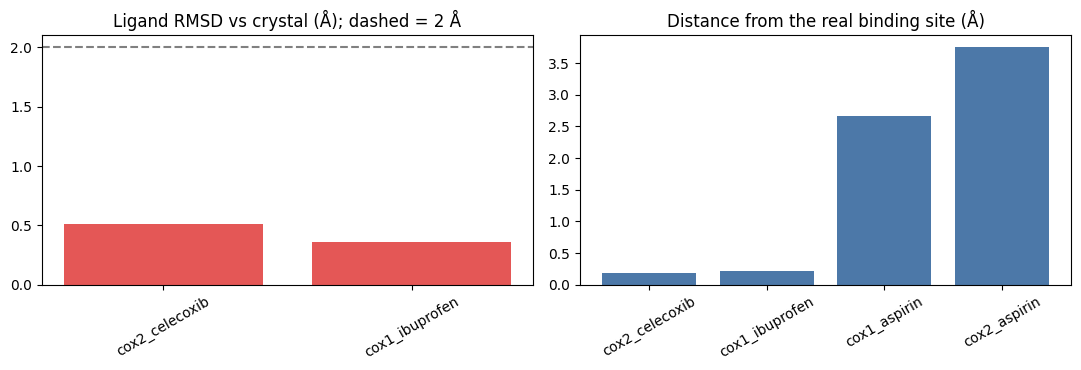

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
with_ref = results.dropna(subset=["Ligand RMSD (Å)"])
ax[0].bar(with_ref["Job"], with_ref["Ligand RMSD (Å)"], color="#E45756")
ax[0].axhline(2, ls="--", color="gray"); ax[0].set_title("Ligand RMSD vs crystal (Å); dashed = 2 Å")
ax[0].tick_params(axis="x", rotation=30)
ax[1].bar(results["Job"], results["Site distance (Å)"], color="#4C78A8")
ax[1].set_title("Distance from the real binding site (Å)")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("day3_cofolding.png", dpi=150); plt.show()

## 7. 3D check
Gray: crystal protein · magenta: crystal drug · rainbow: predicted protein (colored by confidence) · green: predicted drug.

In [ ]:
def show(enz, drug):
    name = f"{enz}_{drug}"
    v = py3Dmol.view(width=600, height=480)
    v.addModel(open(f"exp_{enz}_view.pdb").read(), "pdb")
    v.setStyle({"model": 0}, {"cartoon": {"color": "lightgray", "opacity": 0.6}})
    v.setStyle({"model": 0, "hetflag": True}, {"stick": {"colorscheme": "magentaCarbon"}})
    v.addModel(open(f"pred_{name}_aligned.pdb").read(), "pdb")
    v.setStyle({"model": 1, "chain": "A"}, {"cartoon": {"colorscheme": {"prop": "b", "gradient": "roygb", "min": 50, "max": 90}}})
    v.setStyle({"model": 1, "chain": "B"}, {"stick": {"colorscheme": "greenCarbon"}})
    v.zoomTo({"model": 1, "chain": "B"})
    return v

In [ ]:
show("cox2", "celecoxib").show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [37]:
show("cox1", "aspirin").show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [35]:
show("cox1", "ibuprofen").show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [36]:
show("cox2", "aspirin").show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 8. Summary for your README
Paste the table below into your README, and write down the honest reading.

In [26]:
cols = list(results.columns)
print("| " + " | ".join(cols) + " |")
print("|" + "---|" * len(cols))
for _, r in results.iterrows():
    print("| " + " | ".join("n/a" if pd.isna(r[c]) else str(r[c]) for c in cols) + " |")

| Job | Protein RMSD (Å) | Ligand RMSD (Å) | Site distance (Å) | Key residues touched | Ser530 OG distance (Å) | ipTM | Ligand ipTM | Complex pLDDT |
|---|---|---|---|---|---|---|---|---|
| cox2_celecoxib | 0.35 | 0.51 | 0.19 | none | n/a | 0.67 | 0.67 | 0.93 |
| cox1_ibuprofen | 0.4 | 0.36 | 0.21 | ARG120, TYR355 | 4.11 | 0.83 | 0.83 | 0.95 |
| cox1_aspirin | 0.4 | n/a | 2.67 | TYR385, SER530 | 2.87 | 0.6 | 0.6 | 0.95 |
| cox2_aspirin | 0.46 | n/a | 3.75 | none | n/a | 0.76 | 0.76 | 0.94 |


## What to write in your README
- Did the model place each drug in the real pocket? (site distance)
- Where a crystal drug exists, was the pose correct (ligand RMSD under 2 Å)?
- Did aspirin get close to Ser530? Which key residues did each drug touch?
- Did higher confidence (ipTM) go with more accurate poses? With only a few predictions, say that this is anecdotal.
- Did celecoxib in COX-2 reach the side pocket, as the crystal structure shows?

## Limitations
- Only a handful of predictions, one random seed each. Results can change from run to run.
- **Training overlap:** Boltz was trained on PDB structures, which almost certainly include 1EQG and 3LN1, so success here may reflect memory rather than true prediction. A stronger test would use a COX structure released after the model's training cutoff.
- Aspirin has no crystal ligand in these entries, so its pose can only be judged by site and residue contacts.
- Ligand RMSD depends on matching atoms correctly; a failure message in the table means that value was skipped.
- The crystal structures are single snapshots, not the whole conformational story.

## Next (Stage 4)
Benchmark: co-folding poses vs your Vina docking poses vs the crystal structure, side by side.

## 9. Bundle the outputs
Download the zip, then upload its files to your repo's `results/` folder.

In [30]:
import shutil
os.makedirs("day3_outputs", exist_ok=True)
for f in ["day3_summary.csv", "day3_cofolding.png"] + glob.glob("pred_*_aligned.pdb"):
    if os.path.exists(f):
        shutil.copy(f, "day3_outputs")
shutil.make_archive("day3_outputs", "zip", "day3_outputs")
print("Done: download day3_outputs.zip (Kaggle: Output tab on the right; Colab: Files panel on the left)")

Done: download day3_outputs.zip (Kaggle: Output tab on the right; Colab: Files panel on the left)
